# Week 4 — CLIP Image Embeddings
## Generate and inspect reusable image vectors

This notebook uses the project’s `CLIPEmbedder` to encode every image under `data/images`, save the vectors for later retrieval, preview the dataset, and visualize the embedding space. It is the notebook counterpart to `prepare_embeddings.py`.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

from src.config import BATCH_SIZE, EMBEDDINGS_FILE, IMAGE_PATHS_FILE, MODEL_DIR
from src.embeddings import CLIPEmbedder
from src.utils import get_image_paths, is_valid_image

np.random.seed(42)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
print(f"Image dataset: {Path('data/images').resolve()}")


Image dataset: C:\Users\Diya\Downloads\image_search_engine_week6\image_search_engine_week6\data\images


## 1. Discover and preview the dataset

Only images that PIL can open are embedded. This prevents one damaged file from interrupting the batch process.


Discovered images: 4,769
Valid images:      4,769


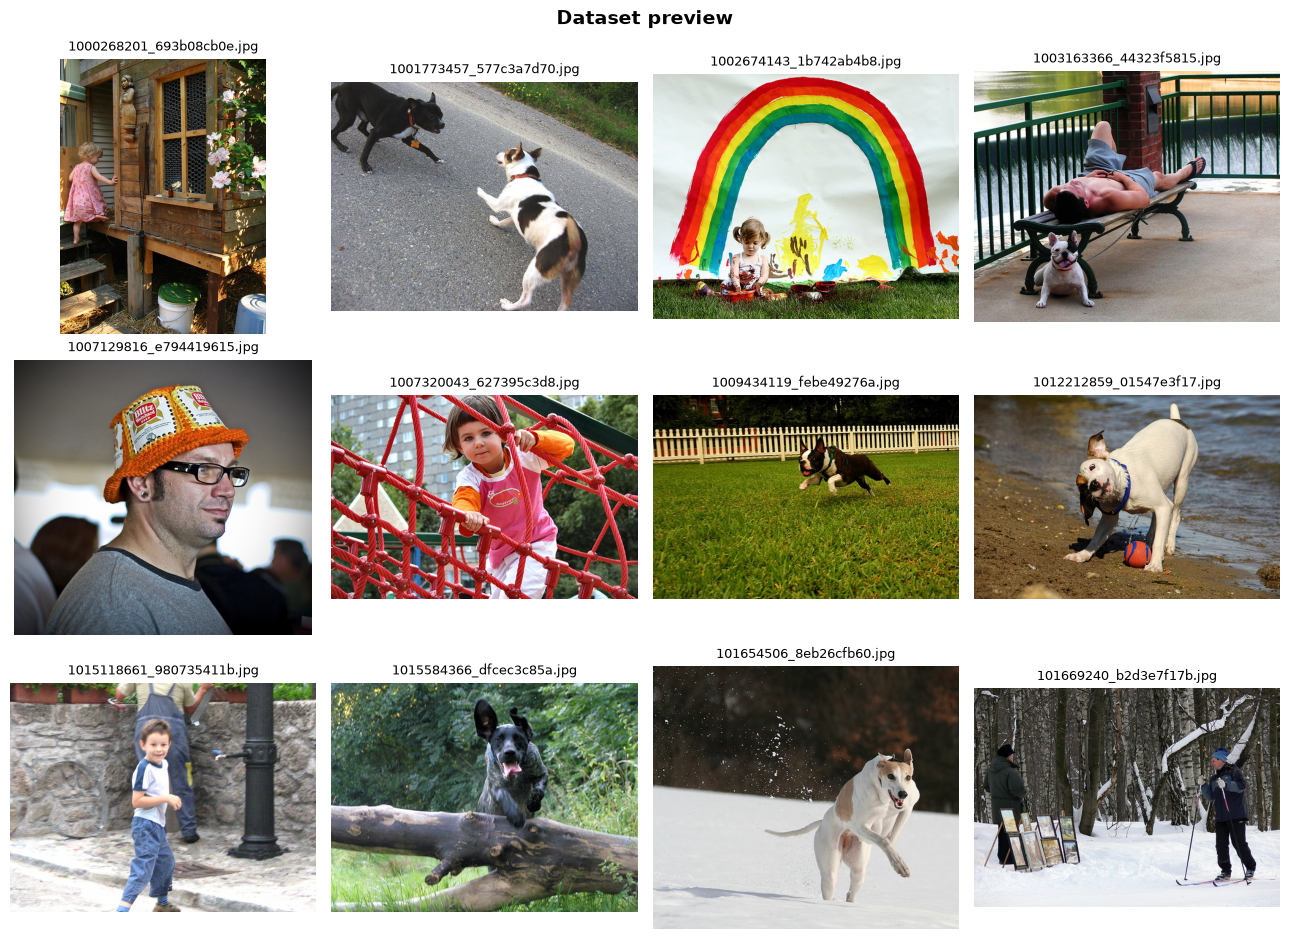

In [2]:
image_paths = get_image_paths(Path("data/images"))
valid_paths = [path for path in image_paths if is_valid_image(path)]

if not valid_paths:
    raise RuntimeError("No valid images found. Add JPG, PNG, WEBP, or BMP files to data/images/ and run this cell again.")

print(f"Discovered images: {len(image_paths):,}")
print(f"Valid images:      {len(valid_paths):,}")

preview_paths = valid_paths[:min(12, len(valid_paths))]
columns = 4
rows = int(np.ceil(len(preview_paths) / columns))
fig, axes = plt.subplots(rows, columns, figsize=(13, 3.2 * rows))
for axis, path in zip(np.ravel(axes), preview_paths):
    with Image.open(path) as image:
        axis.imshow(image.convert("RGB"))
    axis.set_title(path.name, fontsize=9)
    axis.axis("off")
for axis in np.ravel(axes)[len(preview_paths):]:
    axis.axis("off")
plt.suptitle("Dataset preview", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## 2. Generate and save CLIP embeddings

CLIP maps images into a shared vector space. The vectors are L2-normalized by the existing backend, allowing a dot product to represent cosine similarity during Week 5 search.


In [3]:
embedder = CLIPEmbedder()
embeddings, saved_paths = embedder.generate_image_embeddings(valid_paths, batch_size=BATCH_SIZE)

if embeddings.size == 0:
    raise RuntimeError("No embeddings were generated. Check the image files and try again.")

np.save(EMBEDDINGS_FILE, embeddings)
with IMAGE_PATHS_FILE.open("w", encoding="utf-8") as file:
    json.dump(saved_paths, file, indent=2)

print(f"Embedding matrix shape: {embeddings.shape}")
print(f"Saved embeddings: {EMBEDDINGS_FILE}")
print(f"Saved image paths: {IMAGE_PATHS_FILE}")


Loading CLIP model: openai/clip-vit-base-patch32
Using device: cpu


Could not reach the Hub ([WinError 10013] An attempt was made to access a socket in a way forbidden by its access permissions). Using cached commit hash for 'openai/clip-vit-base-patch32'.


Could not reach the Hub ([WinError 10013] An attempt was made to access a socket in a way forbidden by its access permissions). Using cached commit hash for 'openai/clip-vit-base-patch32'.


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Generating image embeddings:   0%|          | 0/299 [00:00<?, ?it/s]

Generating image embeddings:   0%|          | 1/299 [00:01<06:29,  1.31s/it]

... (296 outputs left out)

Generating image embeddings: 100%|█████████▉| 298/299 [07:28<00:01,  1.49s/it]

Generating image embeddings: 100%|██████████| 299/299 [07:28<00:00,  1.08s/it]

Generating image embeddings: 100%|██████████| 299/299 [07:28<00:00,  1.50s/it]

Embedding matrix shape: (4769, 512)
Saved embeddings: C:\Users\Diya\Downloads\image_search_engine_week6\image_search_engine_week6\models\image_embeddings.npy
Saved image paths: C:\Users\Diya\Downloads\image_search_engine_week6\image_search_engine_week6\models\image_paths.json


## 3. Validate the generated vectors

All embeddings should have approximately unit length. The PCA chart is a 2D projection for visual exploration only; retrieval continues to use the full embedding vectors.


## 4. Dataset profile

Image datasets often contain varied aspect ratios and resolutions. These charts make that variation visible before it reaches a model. CLIP preprocesses images internally, but knowing the source distribution is still useful when evaluating results.


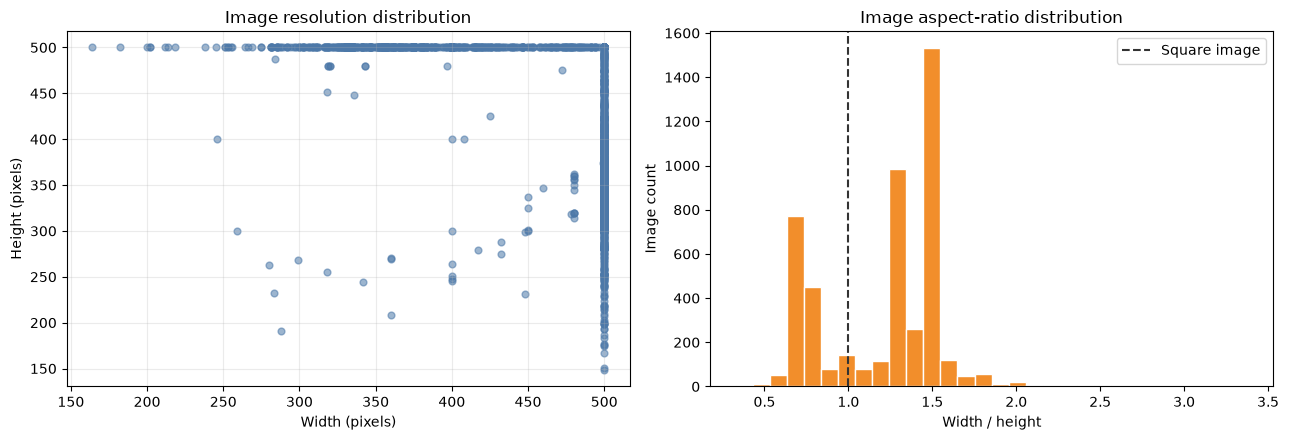

Median resolution: 500 × 375 pixels
Median aspect ratio: 1.33


In [4]:
image_widths, image_heights = [], []
for path in valid_paths:
    with Image.open(path) as image:
        width, height = image.size
        image_widths.append(width)
        image_heights.append(height)

aspect_ratios = np.array(image_widths) / np.array(image_heights)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(image_widths, image_heights, alpha=0.55, s=24, color="#4C78A8")
axes[0].set(title="Image resolution distribution", xlabel="Width (pixels)", ylabel="Height (pixels)")
axes[0].grid(alpha=0.25)
axes[1].hist(aspect_ratios, bins=min(30, len(aspect_ratios)), color="#F28E2B", edgecolor="white")
axes[1].axvline(1, linestyle="--", color="#333333", label="Square image")
axes[1].set(title="Image aspect-ratio distribution", xlabel="Width / height", ylabel="Image count")
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"Median resolution: {np.median(image_widths):.0f} × {np.median(image_heights):.0f} pixels")
print(f"Median aspect ratio: {np.median(aspect_ratios):.2f}")


## 5. Visual similarity inside the embedding space

Because the image vectors are normalized, their dot product is cosine similarity. This section selects one image, ranks the remaining images by visual-semantic closeness, and displays its nearest neighbours. It is an image-to-image sanity check; Week 5 changes the query to text.


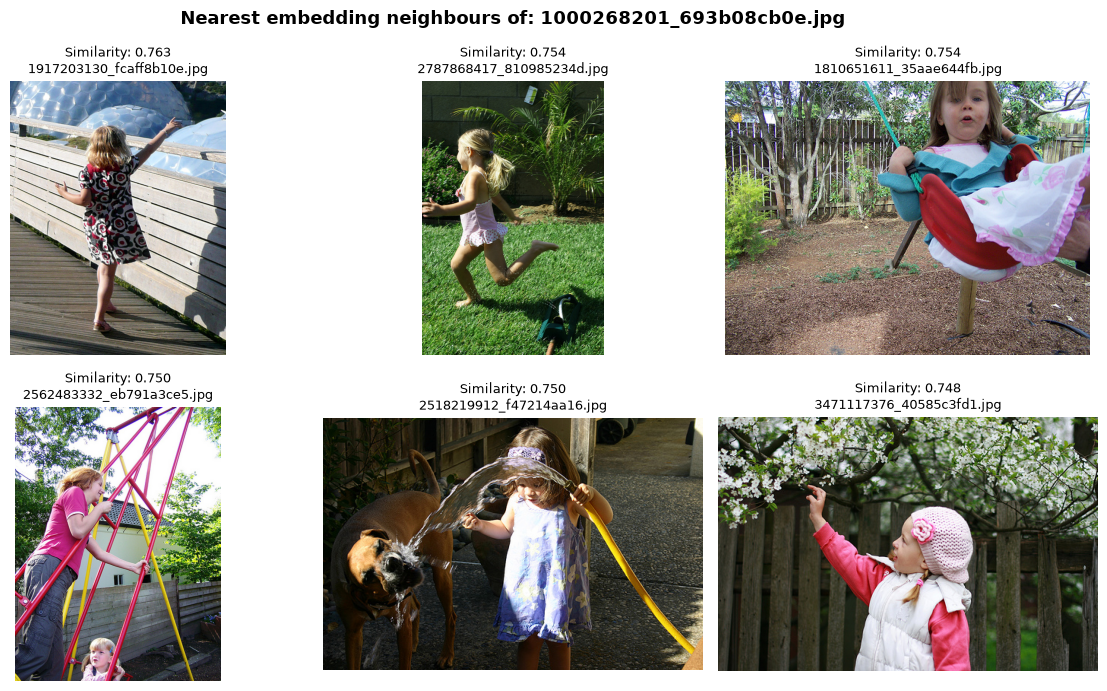

In [5]:
anchor_index = 0
anchor_scores = embeddings @ embeddings[anchor_index]
nearest_indices = np.argsort(-anchor_scores)[1:7]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for axis, index in zip(axes.ravel(), nearest_indices):
    with Image.open(saved_paths[index]) as image:
        axis.imshow(image.convert("RGB"))
    axis.set_title(f"Similarity: {anchor_scores[index]:.3f}\n{Path(saved_paths[index]).name}", fontsize=9)
    axis.axis("off")
plt.suptitle(f"Nearest embedding neighbours of: {Path(saved_paths[anchor_index]).name}", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


## Completion checklist

- `models/image_embeddings.npy` contains one normalized CLIP vector per valid image.
- `models/image_paths.json` keeps each vector aligned with its source filename.
- Dataset and embedding diagnostics provide evidence that the index was built correctly.
- These two files are consumed directly by the Week 5 notebook, CLI, and Streamlit application.
